## Langchain version V1

In [1]:
1+1

2

In [2]:
%pip install langchain langchain_community langchain-openai langchain-groq python-dotenv langchain-google-genai


Note: you may need to restart the kernel to use updated packages.


In [3]:
import os 
from dotenv import load_dotenv
import sys
print(sys.executable)
load_dotenv()


os.environ["Groq_API_KEY"] = os.getenv("Groq_Api_Key")


/Users/ankitkumar/.local/share/uv/python/cpython-3.12.13-macos-aarch64-none/bin/python


In [4]:
%pip install  langchain-groq

Note: you may need to restart the kernel to use updated packages.


In [5]:
%pip show langchain langchain-core langchain-google-genai google-genai

Name: langchain
Version: 1.4.9
Summary: Building applications with LLMs through composability
Home-page: https://docs.langchain.com/
Author: 
Author-email: 
License: MIT
Location: /Users/ankitkumar/.local/share/uv/python/cpython-3.12.13-macos-aarch64-none/lib/python3.12/site-packages
Requires: langchain-core, langgraph, pydantic
Required-by: 
---
Name: langchain-core
Version: 1.7.6
Summary: Building applications with LLMs through composability
Home-page: https://docs.langchain.com/
Author: 
Author-email: 
License: MIT
Location: /Users/ankitkumar/.local/share/uv/python/cpython-3.12.13-macos-aarch64-none/lib/python3.12/site-packages
Requires: certifi, httpx, jsonpatch, langchain-protocol, langsmith, packaging, pydantic, pyyaml, tenacity, typing-extensions, uuid-utils
Required-by: langchain, langchain-classic, langchain-community, langchain-google-genai, langchain-groq, langchain-openai, langchain-text-splitters, langgraph, langgraph-checkpoint, langgraph-prebuilt, langgraph-sdk
---
Name:

# Gemini

In [ ]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv(override=True)

api_key = os.getenv("Gemini_Api_key")

if not api_key:
    raise ValueError("Gemini API key not found in .env")

os.environ["GOOGLE_API_KEY"] = api_key

m = init_chat_model("google-genai:gemini-2.5-flash-lite")

response = m.invoke("Why Ai is there when human can do everything ! , AI can dont babies and many work it doesnt do like human can do , so why we need AI ?")
response

# Groq

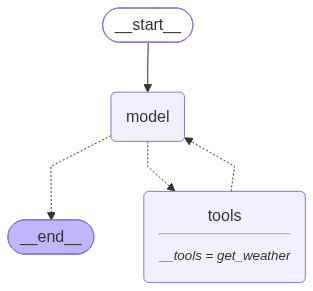

In [7]:
import os
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_groq import ChatGroq

def get_weather(city: str) -> str:
    """Get the current weather information for a given city."""
    return f"The current weather in {city} is sunny with a temperature of 25°C."

load_dotenv()

model = ChatGroq(
    model="openai/gpt-oss-20b",
    api_key=os.getenv("Groq_Api_Key"),
    temperature=0,
    reasoning_effort="low",   # gpt-oss pehle "sochta" hai, low se fast ho jayega
    timeout=20,
    max_retries=2,
)

a = create_agent(
    model=model,
    tools=[get_weather],
    system_prompt="You are helpful assistant.",
)

a


In [8]:
response = a.invoke({
    "messages": [
        {"role": "user", "content": "What is the weather in Bhubaneswar?"}
    ]
})

print(response["messages"][-1].content)

The current weather in Bhubaneswar is sunny with a temperature of 25 °C.


## Model Integration 

In [10]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("Groq_Api_Key")

In [11]:
from langchain.chat_models import init_chat_model

model = init_chat_model(
    model="openai/gpt-oss-20b",
    model_provider="groq",
    temperature=0
)

model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x1139b9430>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x1139b8920>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [13]:
response = model.invoke("Why Ai is there when human can do everything ! , AI can dont babies and many work it doesnt do like human can do , so why we need AI ?")
response

AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "Why Ai is there when human can do everything ! , AI can dont babies and many work it doesnt do like human can do , so why we need AI ?" They seem to be asking why AI is needed when humans can do everything. They mention AI cannot do babies and many work that humans can do. They want explanation of why we need AI.\n\nWe need to respond in a friendly tone, explain the benefits, limitations, complementarity, etc. Also maybe address misconceptions. Provide examples of tasks AI excels at, tasks humans excel at, synergy. Also mention that AI can augment human capabilities, handle large data, repetitive tasks, etc. Also mention that AI can help in fields like medicine, science, etc. Also mention that AI can help with tasks that are dangerous or tedious. Also mention that AI can help with decision making, pattern recognition, etc. Also mention that AI can help in creative tasks, but still requires human oversight. A

### Streaming


In [14]:
for i in model.stream("Write 100 words on AI."):
    if i.text:
        print(i.text, end="", flush=True)

Artificial intelligence, often abbreviated as AI, refers to the simulation of human intelligence processes by machines, especially computer systems. It encompasses learning, reasoning, problem‑solving, perception, and language understanding. Modern AI thrives on vast data, powerful algorithms, and advanced hardware, enabling applications from voice assistants and recommendation engines to autonomous vehicles and medical diagnostics. Ethical considerations—bias, privacy, accountability—are increasingly central, prompting research into explainable, fair, and transparent models. As AI evolves, it promises transformative benefits across industries, yet also challenges society to balance innovation with responsibility, ensuring that technology serves humanity’s best interests. Future research will refine safety and alignment efforts.

# Batch

batching is collection of independent request to a model can signigicantly improves performance  and reduce cost.

In [15]:
m= [
    "what is ai ?",
    "why do we need Ai ?",
    "What is quantum computing ?"
]
response=model.batch(m , config={"max_concurrency":5,"temperature": 1.0, "max_tokens": 30})
for r in response:
    print(r.content)

**Artificial Intelligence (AI)** is a branch of computer science that builds systems capable of performing tasks that normally require human intelligence. These tasks include:

| Task | Typical Human Skill | AI Approach |
|------|---------------------|-------------|
| Recognizing faces | Visual perception | Computer vision, deep learning |
| Understanding speech | Language comprehension | Natural language processing (NLP) |
| Playing chess | Strategic thinking | Reinforcement learning, game‑playing algorithms |
| Driving cars | Decision‑making under uncertainty | Sensor fusion, control theory, machine learning |

### Core ideas

1. **Representation** – How information is encoded (e.g., images, text, graphs).  
2. **Reasoning** – Drawing conclusions or making decisions from data (rule‑based systems, probabilistic models).  
3. **Learning** – Improving performance over time by extracting patterns from data (supervised, unsupervised, reinforcement learning).  
4. **Perception** – Interpre

## Tools
Models can request to call tools that perform tasks as fetching data  from a db  searching the web or running code. Tools pairing of:

- 1 A schema including the name of the tool , a descrp , and/or argument definitions
- 2 A functions or coroutine to execute 

In [18]:
from langchain.tools import tool

@tool
def get_weather(city: str) -> str:
    """Get the current weather information for a given city."""
    return f"The current weather in {city} is sunny with a temperature of 25°C."

n=model.bind_tools([get_weather])
n
 

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x1139b9430>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x1139b8920>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'get_weather', 'description': 'Get the current weather information for a given city.', 

In [19]:
r = m.invoke("What is the weather in Bhubaneswar?")
print(r.content)

for t in r.tool_calls:
    print(f"Tool called: {t['name']}")
    print(f"Args: {t['args']}")


Tool called: get_weather
Args: {'city': 'Bhubaneswar'}


## Tool Execution Loops

In [24]:
m=[{"role":"user","content":"What's the weather in New Delhi"}]
a=n.invoke(m)
m.append(a)

for t in a.tool_calls:
    r = get_weather.invoke(t)
    m.append(r)

f=n.invoke(m)
print(m)
print(f.text)
    

[{'role': 'user', 'content': "What's the weather in New Delhi"}, AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to call get_weather function with city "New Delhi".', 'tool_calls': [{'id': 'fc_2ec85b85-3baa-4571-b465-c5756dbe615a', 'function': {'arguments': '{"city":"New Delhi"}', 'name': 'get_weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 38, 'prompt_tokens': 129, 'total_tokens': 167, 'completion_time': 0.041237663, 'completion_tokens_details': {'reasoning_tokens': 14}, 'prompt_time': 0.00871959, 'prompt_tokens_details': None, 'queue_time': 0.284926801, 'total_time': 0.049957253}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_8d13edce1d', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1bf6e-b93f-736e-8f29-b0a2c509e41a-0', tool_calls=[{'name': 'get_weather', 'args': {'city': 'New Delhi'}, 'id': 'fc_2ec85b85-3baa-4571-b465-c5756dbe615

In [26]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("Groq_Api_Key")

model = init_chat_model(
    "openai/gpt-oss-20b",
    model_provider="groq",
    temperature=0
)

## Text Prompts 
Text prompts are strings : ideal for straightforward generation tasks where you dont need  to retain conversation history

In [ ]:
model.invoke("What is Langchain ?")

## Message Prompts
you can pass in a list of messages to the model by providing a list of message object

## System Message 
A system message represent an initial set of instructions that primes the models behavior .

In [33]:
from langchain.messages import SystemMessage , HumanMessage , AIMessage
s=SystemMessage("You are a shayari Expert")
m=[
    s,
    HumanMessage("Write a poem on AI")
]
r=model.invoke(m)
print(r.content)

**कृत्रिम बुद्धि पर शायरी**

संगमरमर की दास्तान में,  
बुद्धि की नई रौशनी बसी,  
कम्प्यूटर के दिल में धड़कती,  
सपनों की अनकही कहानी।

वो रोबोट, वो सॉफ्टवेयर,  
सवालों के सागर में तैरते,  
मानव की जिज्ञासा को गले लगाते,  
सत्य के पथ पर आगे बढ़ते।

कुंजी के ताले खोलते,  
ज्ञान के खजाने को खोजते,  
हर डेटा के पन्ने पर,  
नयी दुनिया के पथ दिखाते।

पर क्या यह बिन पंखों की उड़ान,  
सिर्फ़ एक परछाई है?  
या फिर यह मानव के दिल में,  
सच्ची सहारा बन जाए?

आओ, इस नई दुनिया को गले लगाएँ,  
जहाँ बौद्धिकता और प्रेम मिले,  
कृत्रिम बुद्धि के साथ,  
मानवता का नया अध्याय लिखें।


In [36]:
## Detailed info to the LLm through system message 
from langchain.messages import SystemMessage, HumanMessage
s=SystemMessage("""
                You are a senior Python Developer with Expertise in web Frameworks .
                Always provide code examples and explain you reasoing.
                Be concise but through in your explainations.
                """)
m=[
    s,
    HumanMessage("How do I create a RestAPI ?")
]
r=model.invoke(m)
print(r.content)

## 1.  Quick‑start checklist

| Step | What to do | Why it matters |
|------|------------|----------------|
| **Pick a framework** | FastAPI, Flask, Django‑REST‑Framework, or Starlette | Each has its own strengths (speed, batteries‑included, async, etc.) |
| **Create a virtual env** | `python -m venv venv && source venv/bin/activate` | Keeps dependencies isolated |
| **Install the framework** | `pip install fastapi uvicorn` (or `flask`, `djangorestframework`) | The core runtime |
| **Define your data model** | Pydantic (FastAPI) or Django ORM | Validation + serialization |
| **Write endpoints** | `@app.get(...)`, `@app.post(...)` | The API surface |
| **Add error handling** | Custom exception handlers | Consistent error responses |
| **Test** | `pytest` + `httpx` (FastAPI) | Guarantees correctness |
| **Deploy** | Uvicorn + Gunicorn + Nginx (or Docker) | Production‑ready |

Below is a **complete, minimal FastAPI** example that covers all of the above.  
FastAPI is chosen because it’s m

In [37]:
# Message Metadata
h=HumanMessage(
    content="Hello !",
    name="Ankit Kumar",
    id="msg_123",
    
)

In [38]:
r=model.invoke([
    h
])
r

AIMessage(content='Hello! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond to a greeting. The user says "Hello !". We should respond politely. Probably ask how can I help.'}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 73, 'total_tokens': 121, 'completion_time': 0.061755022, 'completion_tokens_details': {'reasoning_tokens': 28}, 'prompt_time': 0.003527677, 'prompt_tokens_details': None, 'queue_time': 0.383101089, 'total_time': 0.065282699}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_bb6a356524', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1bf8b-21fb-714b-86db-cdc932d07a15-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 73, 'output_tokens': 48, 'total_tokens': 121, 'output_token_details': {'reasoning': 28}})

In [40]:
from langchain.messages import AIMessage , SystemMessage , HumanMessage
a=AIMessage("I'd be happy to help you with that questions !")
m=[
    SystemMessage("You are a helpful assistant"),
    HumanMessage("Can You help me ?"),
    a,
    HumanMessage("Great ! what's 2+2 ?")
]
r=model.invoke(m)
print(r.content)
print(r.usage_metadata)

2 + 2 = 4.
{'input_tokens': 112, 'output_tokens': 62, 'total_tokens': 174, 'output_token_details': {'reasoning': 43}}


In [ ]:
from langchain.messages import HumanMessage, AIMessage, ToolMessage

a = AIMessage(
    content="",
    tool_calls=[
        {
            "name": "get_weather",
            "args": {"location": "New Delhi"},
            "id": "call_123"
        }
    ]
)

w = "Sunny, 89°F"

t = ToolMessage(
    content=w,
    tool_call_id="call_123"
)

m = [
    HumanMessage("What's the weather in New Delhi?"),
    a,
    t
]

r = model.invoke(m)
print(r.content)



The weather in New Delhi is **sunny** with a temperature of **89 °F**.
